# Task 1: Load and visualize an image

Image shape:  (303, 384)
Image type:  uint8
Single pixel:  121


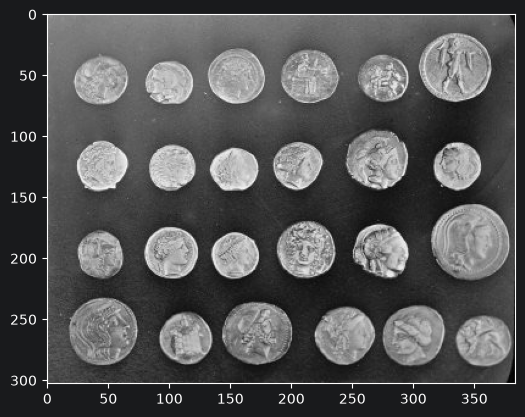

In [99]:
import os
from filecmp import cmp

import skimage
from skimage import io
import matplotlib.pyplot as plt
# Read the coins image which is grayscale (2D)
coins_image = io.imread("coins.jpg")
print("Image shape: ", coins_image.shape)
print("Image type: ", coins_image.dtype)
print("Single pixel: ",coins_image[0,1])
ax = plt.imshow(coins_image, cmap="gray")
plt.show()


Image shape:  (512, 512, 3)
Image type:  uint8
Single pixel:  [ 69  56 109]
One channel of the pixel e.g. red:  69


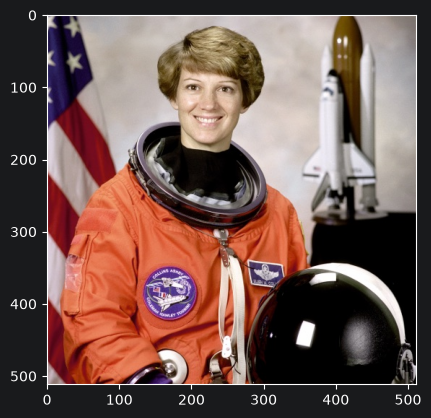

In [100]:
# Read the astronaut image which is RGB(3D)
astronaut_image = io.imread("astronaut.jpg")
print("Image shape: ", astronaut_image.shape)
print("Image type: ", astronaut_image.dtype)
print("Single pixel: ",astronaut_image[100,1])
print("One channel of the pixel e.g. red: ", astronaut_image[100,1,0] ) # 1 is green and 2 is blue
ax = plt.imshow(astronaut_image)
plt.show()

# Task 2: Color space conversion


Image shape:  (512, 512, 3)
Image type:  uint8
Single pixel:  [ 69  56 109]
Image shape:  (512, 512)
Image type:  float64
Single pixel:  0.24542666666666668
Single pixel in ubyte:  62.583800000000004


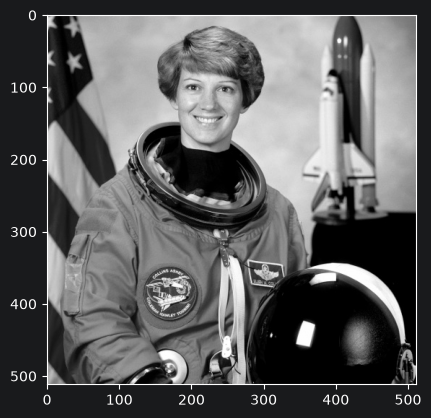

In [101]:
# skimage.color.rgb2gray(coins_image) not possible since it is already grayscal
print("Image shape: ", astronaut_image.shape)
print("Image type: ", astronaut_image.dtype)
print("Single pixel: ",astronaut_image[100,1])
grayscale_astronaut = skimage.color.rgb2gray(astronaut_image)
print("Image shape: ", grayscale_astronaut.shape)
print("Image type: ", grayscale_astronaut.dtype)
print("Single pixel: ",grayscale_astronaut[100,1])
print("Single pixel in ubyte: ",grayscale_astronaut[100,1]*255)
ax = plt.imshow(grayscale_astronaut, cmap="gray")
plt.show()
# The picture goes from a 3D RGB photo (red green blue pixels) to a grayscale 2D (shade of black and white)
# The pixel value goes to a value between 0 and 1 and becomes represented in float (ranges 0-1) to have it in the 0-255 scale multiply with 255

# Task 3: Image rescale and resize

## Image resize

Image shape:  (170, 256)


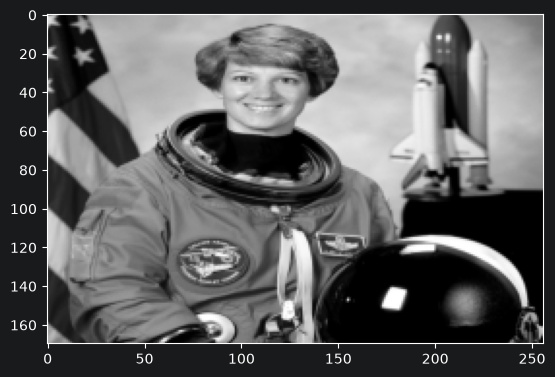

In [102]:
resized_gray_astronaut = skimage.transform.resize(grayscale_astronaut, (grayscale_astronaut.shape[0] // 3, grayscale_astronaut.shape[1] // 2), anti_aliasing=True) # Anti aliasing makes the image smooth
print("Image shape: ", resized_gray_astronaut.shape)
ax = plt.imshow(resized_gray_astronaut, cmap="gray")
plt.show()

## Image rescale

0.25 image shape:  (128, 128)
0.5 image shape:  (256, 256)
0.75 image shape:  (384, 384)


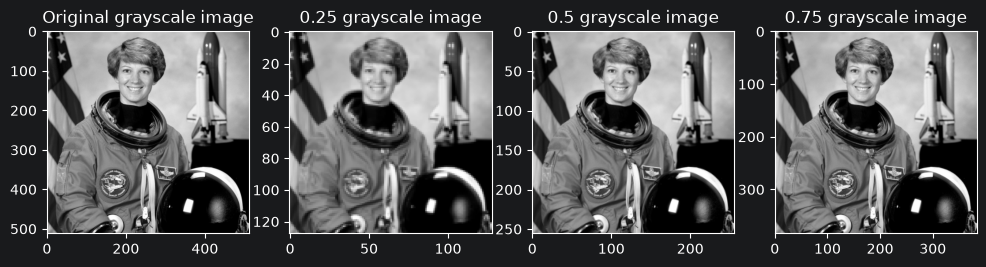

In [103]:
rescale_0_25_gray_astronaut = skimage.transform.rescale(grayscale_astronaut, 0.25, anti_aliasing=True) # Anti aliasing makes the image smooth
print("0.25 image shape: ", rescale_0_25_gray_astronaut.shape)
rescale_0_5_gray_astronaut = skimage.transform.rescale(grayscale_astronaut, 0.5, anti_aliasing=True) # Anti aliasing makes the image smooth
print("0.5 image shape: ", rescale_0_5_gray_astronaut.shape)
rescale_0_75_gray_astronaut = skimage.transform.rescale(grayscale_astronaut, 0.75, anti_aliasing=True) # Anti aliasing makes the image smooth
print("0.75 image shape: ", rescale_0_75_gray_astronaut.shape)
fig, axes = plt.subplots(1, 4, figsize=(12, 4))   # 1 row, 3 columns
axes[0].imshow(grayscale_astronaut, cmap="gray")
axes[0].set_title("Original grayscale image")
axes[1].imshow(rescale_0_25_gray_astronaut, cmap="gray")
axes[1].set_title("0.25 grayscale image")
axes[2].imshow(rescale_0_5_gray_astronaut, cmap="gray")
axes[2].set_title("0.5 grayscale image")
axes[3].imshow(rescale_0_75_gray_astronaut, cmap="gray")
axes[3].set_title("0.75 grayscale image")
plt.show()
## The difference between rescale and resize is that in resizing you specify the new size of the axes, whereas in rescale you specify the new size by a factor

# Task 4: Image thresholding

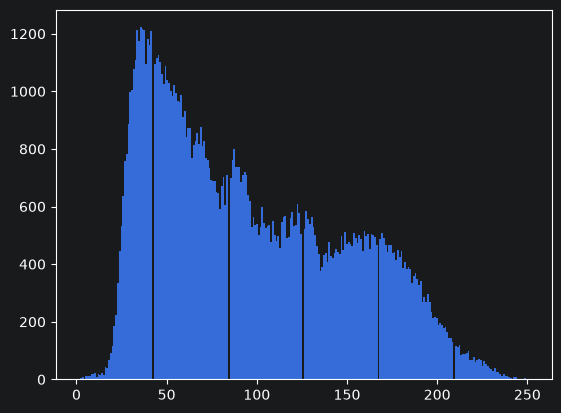

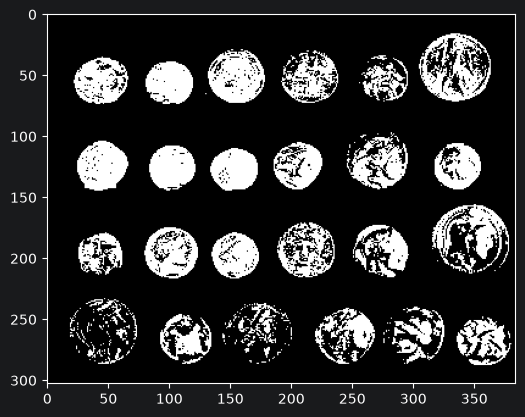

In [118]:
ax = plt.hist(coins_image.ravel(), bins = 256)
binary = coins_image > 150
fig, ax = plt.subplots()
plt.imshow(binary, cmap="gray")
plt.show()

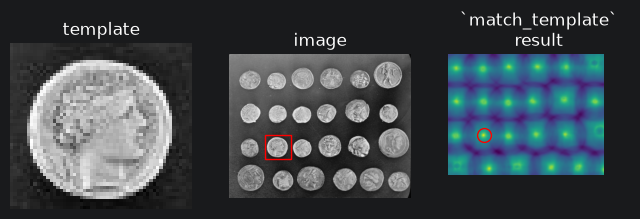

In [105]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.feature import match_template
image = data.coins()
coin = image[170:220, 75:130]
result = match_template(image, coin)
ij = np.unravel_index(np.argmax(result), result.shape)
x, y = ij[::-1]
fig = plt.figure(figsize=(8, 3))
ax1 = plt.subplot(1, 3, 1)
ax2 = plt.subplot(1, 3, 2)
ax3 = plt.subplot(1, 3, 3, sharex=ax2, sharey=ax2)
ax1.imshow(coin, cmap=plt.cm.gray)
ax1.set_axis_off()
ax1.set_title('template')
ax2.imshow(image, cmap=plt.cm.gray)
ax2.set_axis_off()
ax2.set_title('image')
# highlight matched region
hcoin, wcoin = coin.shape
rect = plt.Rectangle((x, y), wcoin, hcoin, edgecolor='r', facecolor='none')
ax2.add_patch(rect)
ax3.imshow(result)
ax3.set_axis_off()
ax3.set_title('`match_template`\nresult')
# highlight matched region
ax3.autoscale(False)
ax3.plot(x, y, 'o', markeredgecolor='r', markerfacecolor='none', markersize=10)
plt.show()

In [106]:
def own_template_matching_using_cross_correlation(template, image):
    image = image.astype(np.float64)
    template = template.astype(np.float64)
    H, W = image.shape # H, W since numpy store row : column
    h, w = template.shape
    result = np.zeros((H - h + 1, W - w + 1))
    for i in range(result.shape[0]):
        for j in range(result.shape[1]):
            win = image[i:i + h, j:j + w]
            result[i, j] = (win * template).sum()
    return result

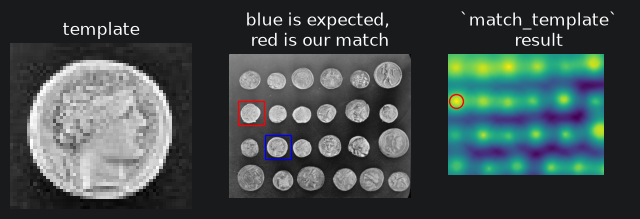

In [107]:
image = data.coins()
coin = image[170:220, 75:130]
result = own_template_matching_using_cross_correlation(coin, image)
ij = np.unravel_index(np.argmax(result), result.shape)
x, y = ij[::-1]
fig = plt.figure(figsize=(8, 3))
ax1 = plt.subplot(1, 3, 1)
ax2 = plt.subplot(1, 3, 2)
ax3 = plt.subplot(1, 3, 3, sharex=ax2, sharey=ax2)
ax1.imshow(coin, cmap=plt.cm.gray)
ax1.set_axis_off()
ax1.set_title('template')
ax2.imshow(image, cmap=plt.cm.gray)
ax2.set_axis_off()
ax2.set_title('blue is expected, \nred is our match')
# highlight matched region
hcoin, wcoin = coin.shape
matched_rect = plt.Rectangle((x, y), wcoin, hcoin, edgecolor='r', facecolor='none')
expected_coin = plt.Rectangle((75, 170), wcoin, hcoin, edgecolor='b', facecolor='none')
ax2.add_patch(matched_rect)
ax2.add_patch(expected_coin)
ax3.imshow(result)
ax3.set_axis_off()
ax3.set_title('`match_template`\nresult')
# highlight matched region
ax3.autoscale(False)
ax3.plot(x, y, 'o', markeredgecolor='r', markerfacecolor='none', markersize=10)
plt.show()
